# Train a neural network

Can one neuron separate two interlocking moons? Compare a single logistic neuron with a multi-layer perceptron (MLP). No downloads are needed. Run the cells in order with **Shift + Enter**.

## Make two moons

Generate points on two noisy arcs. Each point has two coordinates and a label for its arc. Set aside a quarter of the points to check both models on the same unseen data.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

points, labels = make_moons(n_samples=800, noise=0.22, random_state=42)
train_points, test_points, train_labels, test_labels = train_test_split(
    points, labels, test_size=0.25, stratify=labels, random_state=42
)

## Scale the coordinates

Fit the scaler on the training points only. Use those same means and standard deviations to transform the test points. That puts the coordinates on comparable scales without letting the test set influence training.

In [2]:
scaler = StandardScaler().fit(train_points)
train_scaled = scaler.transform(train_points)
test_scaled = scaler.transform(test_points)

## Compare one neuron with hidden layers

Logistic regression acts like one neuron here: it adds two weighted coordinates and a bias, then turns that score into a probability. Its 50% cutoff is a straight line. The MLP passes the coordinates through two layers of 16 hidden neurons before producing a probability. The ReLU activation keeps positive scores and clips negative scores to zero. These nonlinear steps let the network bend the boundary.

In [3]:
def train_mlp(widths, activation):
    return MLPClassifier(
        hidden_layer_sizes=widths, activation=activation,
        learning_rate_init=0.01, max_iter=600, random_state=42,
    ).fit(train_scaled, train_labels)


single = LogisticRegression().fit(train_scaled, train_labels)
mlp = train_mlp((16, 16), "relu")
print(f"Single neuron test accuracy: {single.score(test_scaled, test_labels):.1%}")
print(f"Two hidden layers test accuracy: {mlp.score(test_scaled, test_labels):.1%}")

Single neuron test accuracy: 90.0%
Two hidden layers test accuracy: 95.5%


## Try different hidden layers

Keep the width at 16 and compare one, two, and three hidden layers with `relu` and `tanh`. Unlike ReLU, `tanh` smoothly squeezes scores between −1 and 1. A lower training loss does not always mean better test accuracy. If you want to pick a model rather than explore, make that choice on a separate validation split and save the test split for the final check.

In [4]:
for activation in ("relu", "tanh"):
    for depth in (1, 2, 3):
        trial = mlp if (activation, depth) == ("relu", 2) else train_mlp((16,) * depth, activation)
        print(f"{activation:4} | {depth} hidden layer(s) | "
              f"loss {trial.loss_curve_[-1]:.3f} | test accuracy {trial.score(test_scaled, test_labels):.1%}")

relu | 1 hidden layer(s) | loss 0.095 | test accuracy 96.0%
relu | 2 hidden layer(s) | loss 0.092 | test accuracy 95.5%


relu | 3 hidden layer(s) | loss 0.089 | test accuracy 96.5%


tanh | 1 hidden layer(s) | loss 0.105 | test accuracy 96.0%


tanh | 2 hidden layer(s) | loss 0.091 | test accuracy 96.0%


tanh | 3 hidden layer(s) | loss 0.091 | test accuracy 96.5%


## See it

The pale regions show which class each model predicts. The dark line marks a 50% probability for class 1. The dots are test points colored by their true labels. Compare where the two models put the boundary, then look at how the MLP's training loss changes after each pass through the training set.

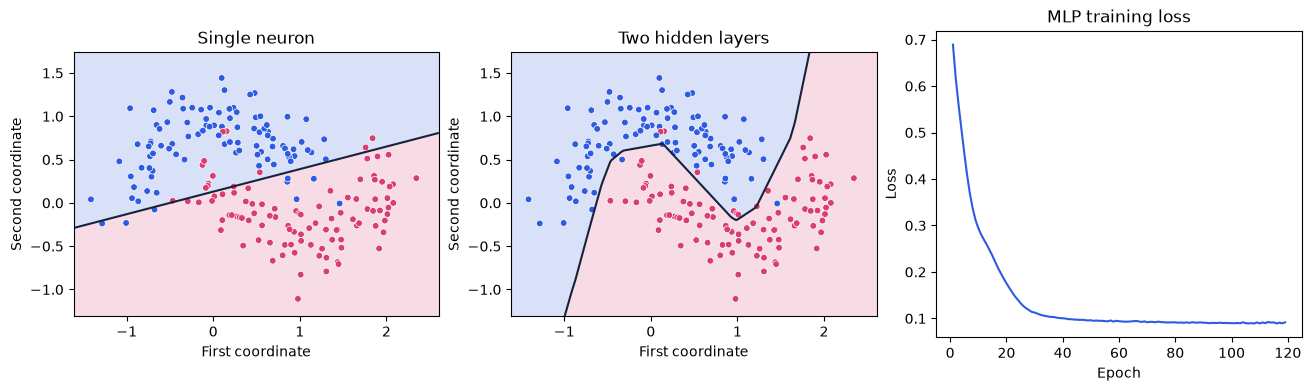

In [5]:
from matplotlib.colors import ListedColormap

colors = ListedColormap(["#2d5be3", "#d93d74"])
first_axis = np.linspace(points[:, 0].min() - 0.2, points[:, 0].max() + 0.2, 160)
second_axis = np.linspace(points[:, 1].min() - 0.2, points[:, 1].max() + 0.2, 160)
grid_x, grid_y = np.meshgrid(first_axis, second_axis)
grid = np.column_stack((grid_x.ravel(), grid_y.ravel()))
grid_scaled = scaler.transform(grid)

fig, (single_ax, mlp_ax, loss_ax) = plt.subplots(1, 3, figsize=(13, 3.8), layout="constrained")
for ax, classifier, title in [(single_ax, single, "Single neuron"), (mlp_ax, mlp, "Two hidden layers")]:
    probability = classifier.predict_proba(grid_scaled)[:, 1].reshape(grid_x.shape)
    ax.contourf(grid_x, grid_y, probability, levels=[0, 0.5, 1], cmap=colors, alpha=0.18)
    ax.contour(grid_x, grid_y, probability, levels=[0.5], colors="#17223b")
    ax.scatter(test_points[:, 0], test_points[:, 1], c=test_labels, cmap=colors,
               edgecolor="white", linewidth=0.5, s=23)
    ax.set(title=title, xlabel="First coordinate", ylabel="Second coordinate", aspect="equal")

loss_ax.plot(range(1, len(mlp.loss_curve_) + 1), mlp.loss_curve_, color="#2d5be3")
loss_ax.set(title="MLP training loss", xlabel="Epoch", ylabel="Loss")
plt.show()